# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertirse titulares peruanos en un clasificador de noticias?

Flujo de este notebook:
1. **Línea base zero-shot** (sin entrenamiento) con `Recognai/bert-base-spanish-wwm-cased-xnli` sobre 40 titulares.
2. **Supervisión débil con LLM**: `qwen2.5:3b` corriendo localmente en **Ollama**, con prompt estructurado y salida JSON validada por esquema → `datos/etiquetas_llm.csv`.
3. **Auditoría humana** de 20 etiquetas del LLM elegidas al azar.
4. **Split estratificado 70/15/15** (`random_state=42`). El test queda aislado hasta el final.
5. **Fine-tuning** de `distilbert-base-multilingual-cased` y BETO con HuggingFace `Trainer`; el modelo y el checkpoint se eligen por F1 macro en **validación**.
6. **Evaluación final en test** + matriz de confusión + comparativa de los tres enfoques.

> **Etiqueta de referencia (gold):** la columna `etiqueta` de `noticias.csv`, derivada de la sección editorial del diario (Parte 1). El LLM se usa como etiquetador débil independiente: se mide contra la sección y se audita manualmente.

In [1]:
import os, json, time, random
from datetime import datetime
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, torch.get_num_threads()))

ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
df = pd.read_csv("datos/noticias.csv").fillna({"bajada": ""})
assert df["titular"].is_unique
print(df.shape)
df["etiqueta"].value_counts()

(400, 7)


etiqueta
ciencia_tecnologia    100
deportes              100
economia              100
politica              100
Name: count, dtype: int64

## 1. Línea base zero-shot (40 titulares)
Muestra estratificada de 10 titulares por categoría. Las etiquetas se presentan al modelo NLI en español natural.

In [2]:
from transformers import pipeline
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error()

ZS_MODELO = "Recognai/bert-base-spanish-wwm-cased-xnli"
zs = pipeline("zero-shot-classification", model=ZS_MODELO, device=-1)
ZS_NOMBRES = {"política": "politica", "economía": "economia", "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}
PLANTILLA = "Esta noticia trata sobre {}."


def zero_shot(titulares):
    out = zs(list(titulares), candidate_labels=list(ZS_NOMBRES), hypothesis_template=PLANTILLA, batch_size=8)
    return [ZS_NOMBRES[o["labels"][0]] for o in out], [o["scores"][0] for o in out]


zs40 = df.groupby("etiqueta", group_keys=False).sample(10, random_state=SEED)
t0 = time.perf_counter()
zs40["pred_zs"], zs40["score_zs"] = zero_shot(zs40["titular"])
lat_zs = (time.perf_counter() - t0) / len(zs40) * 1000
acc_zs40 = accuracy_score(zs40["etiqueta"], zs40["pred_zs"])
f1_zs40 = f1_score(zs40["etiqueta"], zs40["pred_zs"], average="macro")
print(f"Zero-shot (40 titulares)  accuracy = {acc_zs40:.3f}  |  F1 macro = {f1_zs40:.3f}  |  {lat_zs:.0f} ms/titular")
print(classification_report(zs40["etiqueta"], zs40["pred_zs"], labels=ETIQUETAS, zero_division=0))

Zero-shot (40 titulares)  accuracy = 0.650  |  F1 macro = 0.638  |  78 ms/titular
                    precision    recall  f1-score   support

          politica       0.69      0.90      0.78        10
          economia       0.67      0.60      0.63        10
          deportes       0.64      0.70      0.67        10
ciencia_tecnologia       0.57      0.40      0.47        10

          accuracy                           0.65        40
         macro avg       0.64      0.65      0.64        40
      weighted avg       0.64      0.65      0.64        40



In [3]:
print("Errores del zero-shot:")
zs40.loc[zs40.pred_zs != zs40.etiqueta, ["titular", "etiqueta", "pred_zs", "score_zs"]]

Errores del zero-shot:


,titular,etiqueta,pred_zs,score_zs
53,El tamaño medio de las poblaciones mundiales d...,ciencia_tecnologia,economia,0.279599
45,¿Por qué un gran danés vive menos que un chihu...,ciencia_tecnologia,economia,0.446440
44,Informe Planeta Vivo 2026: la fauna silvestre ...,ciencia_tecnologia,politica,0.335622
22,"Google lanza Gemini 4 Argon, su nuevo modelo d...",ciencia_tecnologia,deportes,0.421502
329,En 1993 se liberaron 300 bisontes en una prade...,ciencia_tecnologia,politica,0.325539
0,Fenómeno El Niño Costero: ¿cuáles pueden ser l...,ciencia_tecnologia,deportes,0.632394
132,Mourinho sorprende con mensaje sobre Vinícius:...,deportes,politica,0.439764
93,El furioso “Que se dedique a administrar” de G...,deportes,politica,0.757645
95,Cienciano vs UTC Cajamarca EN VIVO: transmisió...,deportes,ciencia_tecnologia,0.492499
210,IATA sobre la TUUA de conexión internacional: ...,economia,deportes,0.547477


**Piso mínimo a superar:** el F1 macro anterior.

El zero-shot falla sobre todo en `ciencia_tecnologia` (recall 0.40): noticias de biología y ambiente (bisontes de Oklahoma, Informe Planeta Vivo, El Niño costero) no se asocian con la hipótesis *"ciencia y tecnología"* y terminan como política, economía o deportes. También lee como política las declaraciones entre comillas de deportes (Mourinho, Guede) y no reconoce jerga económica específica (TUUA, Nasdaq, contratos).

## 2. Supervisión débil con LLM local (Ollama + Qwen 2.5 3B)
* Prompt con definición de cada categoría y reglas de desempate.
* `format` = **esquema JSON** (Ollama restringe la generación a ese esquema) → la categoría siempre es una de las 4 válidas.
* `temperature = 0` para que sea reproducible.
* Caché: si `datos/etiquetas_llm.csv` ya contiene un titular, no se vuelve a consultar.

In [4]:
OLLAMA_URL = "http://localhost:11434/api/chat"
MODELO_LLM = "qwen2.5:3b"
LLM_CSV = Path("datos/etiquetas_llm.csv")

SISTEMA = '''Eres un editor de un diario peruano. Clasifica la noticia en UNA de estas 4 categorías:
- politica: Gobierno, Congreso, partidos, elecciones, presidentes, ministros, Poder Judicial, Fiscalía, corrupción, política internacional.
- economia: mercados, dólar, precios, inflación, empresas, empleo, impuestos, BCR, minería, comercio, finanzas personales.
- deportes: fútbol, selección, clubes, Liga 1, campeonatos, atletas y cualquier competencia deportiva.
- ciencia_tecnologia: ciencia, espacio, salud e investigación científica, medio ambiente, tecnología, celulares, apps, internet, inteligencia artificial, videojuegos.
Reglas: si una noticia de gobierno trata principalmente de dinero, precios o empresas, es economia. Si trata de leyes, autoridades o conflictos de poder, es politica.
Responde solo con JSON: {"categoria": <categoria>, "confianza": <número entre 0 y 1 que indica qué tan seguro estás>}.'''

ESQUEMA = {"type": "object",
           "properties": {"categoria": {"type": "string", "enum": ETIQUETAS},
                          "confianza": {"type": "number", "minimum": 0, "maximum": 1}},
           "required": ["categoria", "confianza"]}


def etiquetar_llm(titular, bajada):
    usuario = f"Titular: {titular}\nBajada: {bajada or '(sin bajada)'}"
    r = requests.post(OLLAMA_URL, timeout=120, json={
        "model": MODELO_LLM, "stream": False, "format": ESQUEMA, "keep_alive": "30m",
        "options": {"temperature": 0, "seed": SEED, "num_predict": 40},
        "messages": [{"role": "system", "content": SISTEMA}, {"role": "user", "content": usuario}]})
    r.raise_for_status()
    out = json.loads(r.json()["message"]["content"])
    return out["categoria"], round(float(out["confianza"]), 3)


previas = pd.read_csv(LLM_CSV) if LLM_CSV.exists() else pd.DataFrame(columns=["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha"])
hechos = set(previas["titular"])
pendientes = df[~df["titular"].isin(hechos)]
print(f"En caché: {len(hechos)} | por etiquetar: {len(pendientes)}")

nuevas, tiempos = [], []
for i, r in enumerate(pendientes.itertuples(), 1):
    t0 = time.perf_counter()
    cat, conf = etiquetar_llm(r.titular, r.bajada)
    tiempos.append(time.perf_counter() - t0)
    nuevas.append(dict(titular=r.titular, etiqueta_llm=cat, confianza=conf, modelo_llm=f"ollama/{MODELO_LLM}",
                       fecha=datetime.now().strftime("%Y-%m-%d")))
    if i % 25 == 0 or i == len(pendientes):
        pd.concat([previas, pd.DataFrame(nuevas)]).to_csv(LLM_CSV, index=False)   # guardado incremental
        print(f"  {i}/{len(pendientes)}  ({np.mean(tiempos):.2f} s/titular)")

llm = pd.read_csv(LLM_CSV)
llm = llm[llm["titular"].isin(df["titular"])].drop_duplicates("titular")
llm.to_csv(LLM_CSV, index=False)
print("datos/etiquetas_llm.csv:", llm.shape)
llm.head()

En caché: 400 | por etiquetar: 0
datos/etiquetas_llm.csv: (400, 5)


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Fenómeno El Niño Costero: ¿cuáles pueden ser l...,ciencia_tecnologia,0.8,ollama/qwen2.5:3b,2026-10-18
1,Intel en Latinoamérica: “Los gobiernos deben c...,ciencia_tecnologia,0.9,ollama/qwen2.5:3b,2026-10-18
2,Tesla presenta un Roadster capaz de ‘volar’ y ...,ciencia_tecnologia,0.8,ollama/qwen2.5:3b,2026-10-18
3,Padre de la IA y otros 224 científicos piden “...,ciencia_tecnologia,0.9,ollama/qwen2.5:3b,2026-10-18
4,Millones de personas podrían tener que abandon...,ciencia_tecnologia,0.8,ollama/qwen2.5:3b,2026-10-18


In [5]:
# Latencia del LLM medida sobre 10 titulares (independiente de la caché)
t0 = time.perf_counter()
for r in df.sample(10, random_state=SEED).itertuples():
    etiquetar_llm(r.titular, r.bajada)
lat_llm = (time.perf_counter() - t0) / 10 * 1000

d = df.merge(llm, on="titular")
acc_llm_all = accuracy_score(d["etiqueta"], d["etiqueta_llm"])
f1_llm_all = f1_score(d["etiqueta"], d["etiqueta_llm"], average="macro")
print(f"LLM vs sección (dataset completo, n={len(d)}): accuracy = {acc_llm_all:.3f} | F1 macro = {f1_llm_all:.3f} | {lat_llm:.0f} ms/titular")
print(classification_report(d["etiqueta"], d["etiqueta_llm"], labels=ETIQUETAS, zero_division=0))
print("Confianza media del LLM cuando coincide con la sección:", d.loc[d.etiqueta == d.etiqueta_llm, "confianza"].mean().round(3),
      "| cuando no coincide:", d.loc[d.etiqueta != d.etiqueta_llm, "confianza"].mean().round(3))

LLM vs sección (dataset completo, n=400): accuracy = 0.875 | F1 macro = 0.873 | 3788 ms/titular
                    precision    recall  f1-score   support

          politica       0.78      0.99      0.87       100
          economia       0.87      0.73      0.79       100
          deportes       0.99      0.98      0.98       100
ciencia_tecnologia       0.89      0.80      0.84       100

          accuracy                           0.88       400
         macro avg       0.88      0.88      0.87       400
      weighted avg       0.88      0.88      0.87       400

Confianza media del LLM cuando coincide con la sección: 0.92 | cuando no coincide: 0.86


### 2.1 Auditoría humana (20 predicciones al azar)
Se eligieron 20 etiquetas del LLM con `random_state=42`. El estudiante leyó cada titular y bajada y anotó en `datos/auditoria_humana.csv` la categoría que él/ella asignaría (`etiqueta_humana`) y un comentario cuando no coincide.

In [6]:
AUD_CSV = Path("datos/auditoria_humana.csv")
muestra_aud = llm.sample(20, random_state=SEED).merge(df[["titular", "bajada", "medio"]], on="titular")
if not AUD_CSV.exists():
    muestra_aud.assign(etiqueta_humana="", comentario="")[["titular", "bajada", "medio", "etiqueta_llm", "confianza", "etiqueta_humana", "comentario"]] \
        .to_csv(AUD_CSV, index=False)
    print("Plantilla creada: completa la columna etiqueta_humana en", AUD_CSV)

aud = pd.read_csv(AUD_CSV).fillna({"etiqueta_humana": "", "comentario": ""})
assert set(aud["titular"]) == set(muestra_aud["titular"]), "La auditoría no corresponde a la muestra con semilla 42"
revisadas = aud[aud["etiqueta_humana"].isin(ETIQUETAS)]
acuerdos = int((revisadas["etiqueta_humana"] == revisadas["etiqueta_llm"]).sum())
acuerdo_humano = acuerdos / len(revisadas) if len(revisadas) else float("nan")
print(f"Auditoría humana: {acuerdos}/{len(revisadas)} = {acuerdo_humano:.0%} de acuerdo LLM–humano")
aud[["titular", "etiqueta_llm", "confianza", "etiqueta_humana", "comentario"]]

Auditoría humana: 19/20 = 95% de acuerdo LLM–humano


,titular,etiqueta_llm,confianza,etiqueta_humana,comentario
0,Gobierno destina más de S/16 millones para fin...,economia,0.9,economia,
1,Keiko Fujimori sobre incidentes en Comisión de...,politica,0.9,politica,
2,"Google lanza Fitbit Edge, una pulsera avanzada...",ciencia_tecnologia,1.0,ciencia_tecnologia,
3,IATA sobre la TUUA de conexión internacional: ...,politica,0.9,economia,
4,El furioso “Que se dedique a administrar” de G...,deportes,0.9,deportes,
5,"¿Dónde ver repetición del partido, Real Madrid...",deportes,1.0,deportes,
6,En 1993 se liberaron 300 bisontes en una prade...,ciencia_tecnologia,1.0,ciencia_tecnologia,
7,¡Triunfo en casa! Alianza Lima venció 3-1 a At...,deportes,1.0,deportes,
8,Proyecto de Ley MAPE del gobierno propone que ...,politica,0.9,politica,
9,“Creo que puedo llegar a un top 3 sin que nadi...,deportes,0.9,deportes,


## 3. Partición estratificada 70 / 15 / 15
Se estratifica por `etiqueta` con `random_state=42`. El conjunto de **test no se usa** hasta la sección 5 (ni para entrenar, ni para elegir hiperparámetros o checkpoint).

In [7]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["etiqueta"], random_state=SEED)
assert not set(train_df.url) & set(test_df.url) and not set(val_df.url) & set(test_df.url)

resumen = pd.DataFrame({n: s["etiqueta"].value_counts() for n, s in [("train", train_df), ("val", val_df), ("test", test_df)]})
resumen.loc["TOTAL"] = resumen.sum()
for n, s in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{n:5s}: {len(s):3d} ({len(s) / len(df):.1%})")
pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])[["url", "split"]] \
    .to_csv("datos/split.csv", index=False)
resumen

train: 280 (70.0%)
val  :  60 (15.0%)
test :  60 (15.0%)


,train,val,test
etiqueta,,,
ciencia_tecnologia,70,15,15
deportes,70,15,15
economia,70,15,15
politica,70,15,15
TOTAL,280,60,60


## 4. Fine-tuning de Transformers (selección por validación)
Se entrenan los **dos modelos recomendados** con la misma configuración y se elige el que obtiene mejor **F1 macro en validación**. El test no interviene en esta decisión.

| | `distilbert-base-multilingual-cased` | `dccuchile/bert-base-spanish-wwm-cased` (BETO) |
|---|---|---|
| Capas | 6 (destilado) | 12 |
| Preentrenamiento | 104 idiomas | solo español |

Configuración común: entrada = **solo el titular** (igual que en el probador del dashboard), 5 épocas (≥ 3 exigidas), batch 16, lr 5e-5, `eval_strategy="epoch"`, `metric_for_best_model="f1_macro"` y `load_best_model_at_end=True`. Todo en CPU.

In [8]:
import shutil
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, set_seed)
label2id = {l: i for i, l in enumerate(ETIQUETAS)}
id2label = {i: l for l, i in label2id.items()}


class NoticiasDS(torch.utils.data.Dataset):
    def __init__(self, frame, tok):
        self.enc = tok(list(frame["titular"]), truncation=True, max_length=64)
        self.y = [label2id[e] for e in frame["etiqueta"]]
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.y[i]
        return item


def metricas(eval_pred):
    logits, y = eval_pred
    p = logits.argmax(-1)
    return {"accuracy": accuracy_score(y, p), "f1_macro": f1_score(y, p, average="macro")}


def entrenar(base, carpeta):
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(base)
    modelo = AutoModelForSequenceClassification.from_pretrained(base, num_labels=4, id2label=id2label, label2id=label2id)
    args = TrainingArguments(
        output_dir=f"modelo/checkpoints_{carpeta}", num_train_epochs=5, per_device_train_batch_size=16,
        per_device_eval_batch_size=32, learning_rate=5e-5, weight_decay=0.01, warmup_steps=10,
        eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1_macro",
        greater_is_better=True, save_total_limit=1, logging_strategy="epoch", report_to="none", seed=SEED,
        use_cpu=True, disable_tqdm=True)
    trainer = Trainer(model=modelo, args=args, train_dataset=NoticiasDS(train_df, tok),
                      eval_dataset=NoticiasDS(val_df, tok), data_collator=DataCollatorWithPadding(tok),
                      compute_metrics=metricas)
    t0 = time.perf_counter()
    trainer.train()
    minutos = (time.perf_counter() - t0) / 60
    shutil.rmtree(f"modelo/checkpoints_{carpeta}", ignore_errors=True)
    hist = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
    print(f"{base}: {minutos:.1f} min en CPU | mejor F1 macro en validación = {trainer.state.best_metric:.3f}")
    return dict(base=base, trainer=trainer, tok=tok, val_f1=trainer.state.best_metric, minutos=minutos,
                hist=hist[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].assign(modelo=carpeta))


candidatos = [entrenar("distilbert-base-multilingual-cased", "distilbert"),
              entrenar("dccuchile/bert-base-spanish-wwm-cased", "beto")]

{'loss': '1.315', 'grad_norm': '3.888', 'learning_rate': '4.562e-05', 'epoch': '1'}


{'eval_loss': '1.075', 'eval_accuracy': '0.65', 'eval_f1_macro': '0.6444', 'eval_runtime': '0.6101', 'eval_samples_per_second': '98.34', 'eval_steps_per_second': '3.278', 'epoch': '1'}


{'loss': '0.7083', 'grad_norm': '8.097', 'learning_rate': '3.438e-05', 'epoch': '2'}


{'eval_loss': '0.5276', 'eval_accuracy': '0.8167', 'eval_f1_macro': '0.8165', 'eval_runtime': '0.5195', 'eval_samples_per_second': '115.5', 'eval_steps_per_second': '3.85', 'epoch': '2'}


{'loss': '0.2761', 'grad_norm': '3.925', 'learning_rate': '2.313e-05', 'epoch': '3'}


...

{'eval_loss': '0.6776', 'eval_accuracy': '0.8667', 'eval_f1_macro': '0.8683', 'eval_runtime': '1.135', 'eval_samples_per_second': '52.87', 'eval_steps_per_second': '1.762', 'epoch': '4'}


{'loss': '0.01155', 'grad_norm': '0.0456', 'learning_rate': '6.25e-07', 'epoch': '5'}


{'eval_loss': '0.6877', 'eval_accuracy': '0.8667', 'eval_f1_macro': '0.8683', 'eval_runtime': '1.08', 'eval_samples_per_second': '55.54', 'eval_steps_per_second': '1.851', 'epoch': '5'}


{'train_runtime': '123', 'train_samples_per_second': '11.38', 'train_steps_per_second': '0.732', 'train_loss': '0.264', 'epoch': '5'}


dccuchile/bert-base-spanish-wwm-cased: 2.1 min en CPU | mejor F1 macro en validación = 0.868


In [9]:
pd.concat([c["hist"] for c in candidatos]).round(3).pivot(index="epoch", columns="modelo", values=["eval_f1_macro", "eval_loss"])

eval_f1_macro            eval_loss           
modelo          beto distilbert      beto distilbert
epoch                                               
1.0            0.828      0.644     0.503      1.075
2.0            0.834      0.817     0.610      0.528
3.0            0.852      0.821     0.768      0.503
4.0            0.868      0.780     0.678      0.566
5.0            0.868      0.853     0.688      0.529

In [10]:
mejor = max(candidatos, key=lambda c: c["val_f1"])
BASE = mejor["base"]
print("Modelo elegido por F1 macro en VALIDACIÓN:", BASE, f"({mejor['val_f1']:.3f})")
mejor["trainer"].save_model("modelo")
mejor["tok"].save_pretrained("modelo")
Path("modelo/training_args.bin").unlink(missing_ok=True)
print(sorted(p.name for p in Path("modelo").iterdir()))

Modelo elegido por F1 macro en VALIDACIÓN: dccuchile/bert-base-spanish-wwm-cased (0.868)


['config.json', 'matriz_confusion_test.png', 'metricas.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


## 5. Evaluación final en el conjunto de **test** reservado

In [11]:
clf = pipeline("text-classification", model="modelo", tokenizer="modelo", device=-1)
t0 = time.perf_counter()
pred = clf(list(test_df["titular"]), batch_size=32)
lat_ft = (time.perf_counter() - t0) / len(test_df) * 1000
test_df = test_df.assign(pred_ft=[p["label"] for p in pred], prob_ft=[p["score"] for p in pred])

acc_ft = accuracy_score(test_df["etiqueta"], test_df["pred_ft"])
f1_ft = f1_score(test_df["etiqueta"], test_df["pred_ft"], average="macro")
print(f"TEST (n={len(test_df)})  accuracy = {acc_ft:.3f}  |  F1 macro = {f1_ft:.3f}")
print(classification_report(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS, digits=3, zero_division=0))

TEST (n=60)  accuracy = 0.867  |  F1 macro = 0.865
                    precision    recall  f1-score   support

          politica      0.812     0.867     0.839        15
          economia      0.786     0.733     0.759        15
          deportes      0.938     1.000     0.968        15
ciencia_tecnologia      0.929     0.867     0.897        15

          accuracy                          0.867        60
         macro avg      0.866     0.867     0.865        60
      weighted avg      0.866     0.867     0.865        60



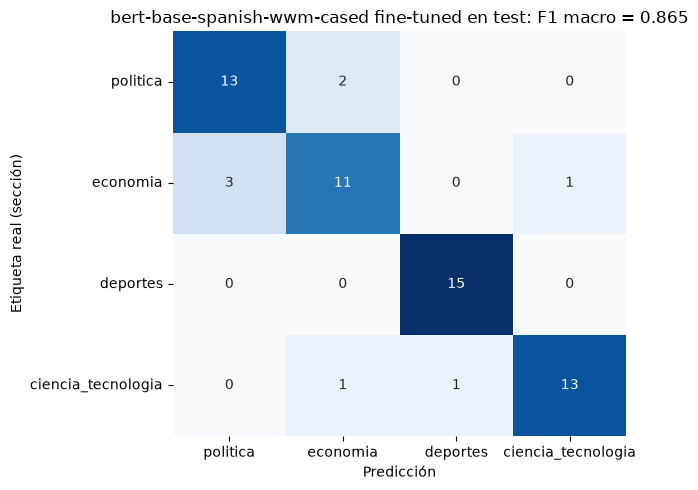

In [12]:
cm = confusion_matrix(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, cbar=False, ax=ax)
ax.set_xlabel("Predicción"); ax.set_ylabel("Etiqueta real (sección)")
ax.set_title(f"{BASE.split('/')[-1]} fine-tuned en test: F1 macro = {f1_ft:.3f}")
plt.tight_layout(); plt.savefig("modelo/matriz_confusion_test.png", dpi=120); plt.show()

In [13]:
print("Errores del modelo en test:")
test_df.loc[test_df.pred_ft != test_df.etiqueta, ["medio", "titular", "etiqueta", "pred_ft", "prob_ft"]]

Errores del modelo en test:


,medio,titular,etiqueta,pred_ft,prob_ft
163,El Comercio,Incendios forestales se multiplicaron por casi...,economia,ciencia_tecnologia,0.498274
57,El Comercio,BTS en Lima: la emoción del concierto es aprov...,ciencia_tecnologia,economia,0.550391
234,El Comercio,Mincetur designa a Roxana Barrantes como nuevo...,economia,politica,0.978575
267,El Comercio,Viceministra de Minas: “Estamos estableciendo ...,politica,economia,0.894701
231,El Comercio,Gobierno designa presidenta del directorio y d...,economia,politica,0.988900
286,El Comercio,Rodrigo Paz visitará el Perú en noviembre para...,politica,economia,0.934130
52,El Comercio,“Ace Combat 8: Wings of Theve” eleva la franqu...,ciencia_tecnologia,deportes,0.983269
373,La Republica,Movistar prepara su red en Lambayeque ante pos...,economia,politica,0.463809


### Reflexión por categoría (test)
* **Mejor: `deportes` (F1 0.968, recall 1.00).** Su léxico es muy específico y casi exclusivo: clubes (Alianza Lima, Universitario, Real Madrid), "Liga 1", "goles", "EN VIVO", marcadores como "3-1". Un titular deportivo casi nunca comparte vocabulario con las otras categorías.
* **Peor: `economia` (F1 0.759).** En el Perú la frontera con `politica` es difusa porque muchas decisiones económicas las anuncia el Gobierno. *"Mincetur designa a Roxana Barrantes…"* y *"Gobierno designa presidenta del directorio… del Fonafe"* están en la sección economía de El Comercio, pero su lenguaje (designa, Gobierno, ministerio) es político. Al revés, *"Viceministra de Minas: …"* (sección política) habla de minería y el modelo la ve como economía. En la auditoría humana, el estudiante también eligió `politica` para la noticia del Fonafe: parte del "error" es ambigüedad de la etiqueta por sección, no solo del modelo.
* **`ciencia_tecnologia` (F1 0.897)** pierde notas de la sección tecnología de El Comercio que tratan otros temas: un videojuego de combate aéreo (*"Ace Combat 8…"*) se lee como deporte y una nota sobre el concierto de BTS en Lima, como economía.
* **`politica` (F1 0.839)** recibe los falsos positivos de economía descritos arriba (precision 0.81), aunque recupera el 87 % de las noticias políticas.

## 6. Comparativa: zero-shot vs. LLM débil vs. Transformer fine-tuned
Los tres enfoques se evalúan sobre **el mismo conjunto de test** (además se muestra el zero-shot de 40 titulares del paso 1).

In [14]:
t_zs, _ = zero_shot(test_df["titular"])
t_llm = test_df.merge(llm, on="titular")["etiqueta_llm"]
y = test_df["etiqueta"]
comp = pd.DataFrame([
    {"modelo": f"Zero-shot NLI ({ZS_MODELO.split('/')[1]})", "entrenamiento": "ninguno",
     "accuracy_test": accuracy_score(y, t_zs), "f1_macro_test": f1_score(y, t_zs, average="macro"),
     "ms_por_titular_cpu": lat_zs, "tamaño": "~440 MB", "costo": "gratis, CPU"},
    {"modelo": f"LLM débil (Ollama {MODELO_LLM})", "entrenamiento": "ninguno (zero-shot)",
     "accuracy_test": accuracy_score(y, t_llm), "f1_macro_test": f1_score(y, t_llm, average="macro"),
     "ms_por_titular_cpu": lat_llm, "tamaño": "~1.9 GB", "costo": "gratis local; requiere servidor Ollama"},
    {"modelo": f"Fine-tuned ({BASE.split('/')[-1]})", "entrenamiento": f"{len(train_df)} titulares, 5 épocas, {mejor['minutos']:.1f} min CPU",
     "accuracy_test": acc_ft, "f1_macro_test": f1_ft, "ms_por_titular_cpu": lat_ft, "tamaño": f"~{Path('modelo/model.safetensors').stat().st_size / 1e6:.0f} MB",
     "costo": "gratis, CPU"},
])
print(f"Zero-shot en los 40 titulares del paso 1: F1 macro = {f1_zs40:.3f}")
comp.round(3)

Zero-shot en los 40 titulares del paso 1: F1 macro = 0.638


,modelo,entrenamiento,accuracy_test,f1_macro_test,ms_por_titular_cpu,tamaño,costo
0,Zero-shot NLI (bert-base-spanish-wwm-cased-xnli),ninguno,0.667,0.648,78.433,~440 MB,"gratis, CPU"
1,LLM débil (Ollama qwen2.5:3b),ninguno (zero-shot),0.833,0.827,3787.904,~1.9 GB,gratis local; requiere servidor Ollama
2,Fine-tuned (bert-base-spanish-wwm-cased),"280 titulares, 5 épocas, 2.1 min CPU",0.867,0.865,22.392,~439 MB,"gratis, CPU"


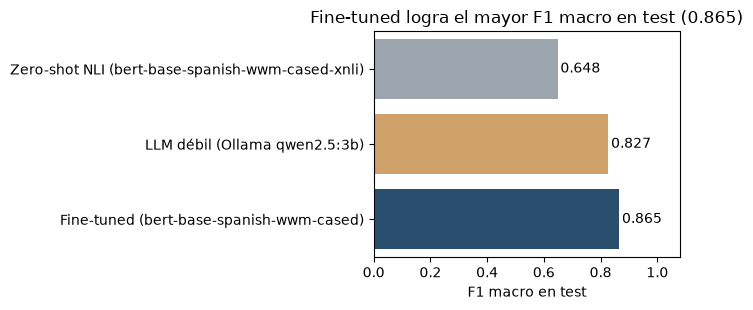

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.barplot(data=comp, y="modelo", x="f1_macro_test", hue="modelo", palette=["#9aa5b1", "#e0a458", "#1f4e79"], legend=False, ax=ax)
for i, v in enumerate(comp["f1_macro_test"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.08); ax.set_xlabel("F1 macro en test"); ax.set_ylabel("")
g = comp.loc[comp["f1_macro_test"].idxmax()]
ax.set_title(f"{g['modelo'].split(' (')[0]} logra el mayor F1 macro en test ({g['f1_macro_test']:.3f})")
plt.tight_layout(); plt.show()

In [16]:
resultados = {
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "n_noticias": int(len(df)), "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
    "f1_macro_test": round(f1_ft, 4), "accuracy_test": round(acc_ft, 4),
    "zero_shot_f1_40": round(f1_zs40, 4), "zero_shot_acc_40": round(acc_zs40, 4),
    "modelo_final": BASE, "val_f1_candidatos": {c["base"]: round(c["val_f1"], 4) for c in candidatos},
    "llm_modelo": f"ollama/{MODELO_LLM}", "llm_f1_dataset": round(f1_llm_all, 4),
    "auditoria_acuerdos": acuerdos, "auditoria_total": int(len(revisadas)),
    "auditoria_pct": None if np.isnan(acuerdo_humano) else round(acuerdo_humano, 4),
    "comparativa": comp.round(4).to_dict(orient="records"),
}
Path("modelo/metricas.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Resultados Test: F1 Macro: {f1_ft:.3f} | Zero-shot: {f1_zs40:.3f} | Acuerdo LLM-Humano: {acuerdos}/{len(revisadas)}")

Resultados Test: F1 Macro: 0.865 | Zero-shot: 0.638 | Acuerdo LLM-Humano: 19/20


## Decisión para un entorno real
**Elegiría el Transformer fine-tuned (BETO)** para clasificar noticias en producción:
* **Precisión:** mejor F1 macro en el mismo test (0.865, contra 0.827 del LLM y 0.648 del zero-shot).
* **Latencia:** ~20 ms por titular en CPU, más de 100 veces más rápido que el LLM (~3.5–4 s por titular).
* **Costo computacional:** ~420 MB, corre en CPU sin GPU ni servidor adicional, y su probabilidad por clase permite fijar umbrales (p. ej., mandar a revisión humana si la confianza es < 0.6).

El **LLM** brilla como *etiquetador*: sin ningún ejemplo etiquetado alcanza 0.83 de F1 y 95 % de acuerdo con la auditoría humana, así que sirve para etiquetar datos nuevos, añadir categorías o detectar errores de la etiqueta por sección. Pero su latencia y memoria (~1.9 GB + servidor Ollama) lo hacen caro para clasificar en vivo. El **zero-shot** solo se justifica como arranque en frío cuando no hay ningún dato.

**Cautela estadística:** el test tiene 60 titulares, así que cada error mueve el F1 en ~0.017. La ventaja de BETO sobre el LLM (~0.04) equivale a unos 2 titulares. Con más datos convendría validación cruzada o un test más grande.